# 線形分離可能なハードマージンSVM：学習過程を追う実験ノートブック

**目的：** 学習データを**10点だけ**に限定し、双対係数 $\lambda$ が更新されるたびに、識別境界 $g(x)=0$・マージン $g(x)=\pm1$・サポートベクトル・目的関数がどう変わるか観察します。

このノートでは、**SMOと同じ「2つの双対係数を選ぶ」考え方**を持つ、教材向けの**ペア座標上昇法**を自作します。一般的なLIBSVMのSMO実装そのものではありませんが、毎回2変数の小さなQPを厳密に解くという基本原理は共通です。

**前提**：2クラス・2次元・線形分離可能、ハードマージン、バイアスあり。利用：`numpy`, `matplotlib`, `scipy`, `pandas`（任意）。

### 教科書との対応
- 主問題：$\min_{w,w_0}\frac12\|w\|^2$、制約 $b_k(w^Tx_k+w_0)\ge1$
- 双対問題：$\max_\lambda\;\mathbf1^T\lambda-\frac12\lambda^TH\lambda$、制約 $\lambda\ge0,\;b^T\lambda=0$
- $H_{ij}=b_i b_j x_i^Tx_j$、$w=\sum_k\lambda_k b_k x_k$
- KKT：$\lambda_k[b_k(w^Tx_k+w_0)-1]=0$

> 注意：更新途中では主問題の全制約を満たしていない場合があります。双対目的関数が増えることと、各途中段階で分類が完全に正しいことは同じではありません。

## 1. 学習データは10点だけ

図を読みやすくするため、正負5点ずつを用意します。赤と青の2クラスが直線で分離できるようにしています。個数や位置を変更する実験は最後に行います。

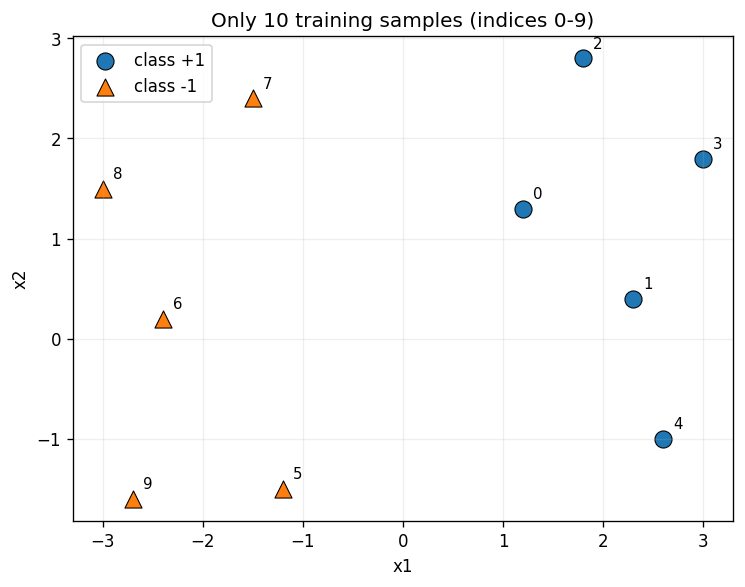

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=5, suppress=True)

X = np.array([
    [ 1.2,  1.3], [ 2.3,  0.4], [ 1.8,  2.8], [ 3.0,  1.8], [ 2.6, -1.0],
    [-1.2, -1.5], [-2.4,  0.2], [-1.5,  2.4], [-3.0,  1.5], [-2.7, -1.6]
], dtype=float)
y = np.array([+1]*5 + [-1]*5, dtype=float)
n_samples = len(X)

fig, ax = plt.subplots(figsize=(7.1, 5.5))
for label, color, mark in [(1, 'tab:blue', 'o'), (-1, 'tab:orange', '^')]:
    mask = y == label
    ax.scatter(X[mask,0], X[mask,1], c=color, marker=mark, s=105,
               edgecolors='black', linewidths=.65, label=f'class {label:+.0f}')
for k, (a, b) in enumerate(X):
    ax.annotate(str(k), (a, b), xytext=(6, 6), textcoords='offset points', fontsize=9)
ax.set(xlabel='x1', ylabel='x2', title='Only 10 training samples (indices 0-9)')
ax.set_aspect('equal', adjustable='box'); ax.grid(alpha=.2); ax.legend()
plt.show()

## 2. 主問題と双対問題を確認する

主問題（$w,w_0$ に関する最小化）：
$$\min_{w,w_0}\frac12\|w\|^2\quad\text{s.t. }y_k(w^Tx_k+w_0)\ge1.$$

双対問題（$\lambda$ に関する最大化）：
$$\boxed{\max_{\lambda\ge0,\;y^T\lambda=0}\;D(\lambda)=\mathbf1^T\lambda-\frac12\lambda^TH\lambda}$$
$$H_{ij}=y_iy_j(x_i^Tx_j),\qquad\nabla D(\lambda)=\mathbf1-H\lambda.$$

双対問題では、$w$ と $w_0$ を直接更新せず、学習データに対応する $\lambda_k$ を更新します。$\lambda_k>0$ となる点が最終的な重みに寄与します。

### $H$ が半正定値になる理由
$Z=\operatorname{diag}(y)X$ とおくと $H=ZZ^T$ だから、任意の $a$ に対して $a^THa=\|Z^Ta\|^2\ge0$ です。よって $D$ は凹二次関数になります。

In [2]:
Z = X * y[:, None]
H = Z @ Z.T
print('H shape:', H.shape)
print('H eigenvalues:', np.linalg.eigvalsh(H).round(7))
print('min eigenvalue (numerical):', np.linalg.eigvalsh(H).min())


def dual_value(lam):
    return float(np.sum(lam) - 0.5 * lam @ H @ lam)

def dual_grad(lam):
    return np.ones(len(lam)) - H @ lam

def reconstruct_w(lam):
    return (lam * y) @ X

H shape: (10, 10)
H eigenvalues: [-0.      -0.      -0.      -0.      -0.       0.       0.       0.
 24.49937 53.76063]
min eigenvalue (numerical): -5.427239884300808e-15


## 3. 2変数更新の仕組みを導出する

$\lambda_i,\lambda_j$ のみ動かし、ほかは固定します。等式制約 $\sum_k y_k\lambda_k=0$ を保つには、更新方向 $d$ が $y^Td=0$ を満たす必要があります。

$$d_i=1,\qquad d_j=-\frac{y_i}{y_j},\qquad d_k=0\;(k\ne i,j).$$

$\lambda' = \lambda + t d$ とすると、
$$D(\lambda+td)=D(\lambda)+t\underbrace{\nabla D(\lambda)^Td}_{a}-\frac{t^2}{2}\underbrace{d^THd}_{q}.$$
$q>0$ なら微分して $t_\mathrm{free}=a/q$。ただし各 $\lambda_k+td_k\ge0$ を満たす区間に切り詰めます。

このノートでは、**すべてのペアを試したときの改善量を計算し、最大の改善をもたらすペアを1回更新**します。通常のSMOと同様、更新量を決める際に1変数の二次最適化を解いています。ただしペア選択方法や停止判定は学習用に簡略化しています。

In [3]:
def pair_candidate(lam, i, j, tol=1e-12):
    d = np.zeros_like(lam)
    d[i] = 1.0
    d[j] = -y[i] / y[j]
    a = float(dual_grad(lam) @ d)
    q = float(d @ H @ d)

    # Feasible interval for lambda + t*d >= 0.
    lo, hi = -np.inf, np.inf
    for k in (i, j):
        bound = -lam[k] / d[k]
        if d[k] > 0:
            lo = max(lo, bound)
        else:
            hi = min(hi, bound)
    if lo > hi + 1e-12:
        return None

    if q > tol:
        t = np.clip(a / q, lo, hi)
    else:
        # With q~0 and bounded direction, move to the better endpoint.
        if abs(a) < tol:
            t = 0.0
        elif a > 0 and np.isfinite(hi):
            t = hi
        elif a < 0 and np.isfinite(lo):
            t = lo
        else:
            return None
    gain = a*t - 0.5*q*t*t
    return float(gain), float(t), d


def fit_dual_pairs(max_steps=15000, tol=1e-12):
    lam = np.zeros(len(y))  # feasible: lambda>=0, y^T lambda = 0
    history = [dict(lam=lam.copy(), pair=None, gain=0., D=dual_value(lam))]
    for step in range(max_steps):
        best = (0.0, None, None, None)
        for i in range(len(y)):
            for j in range(i+1, len(y)):
                candidate = pair_candidate(lam, i, j)
                if candidate is not None and candidate[0] > best[0]:
                    best = (candidate[0], i, j, candidate)
        gain, i, j, candidate = best
        if gain < tol:
            break
        _, t, d = candidate
        lam = lam + t * d
        lam[np.abs(lam) < 1e-12] = 0.0
        history.append(dict(lam=lam.copy(), pair=(i,j), gain=gain, D=dual_value(lam)))
    return history

history = fit_dual_pairs()
print('updates:', len(history)-1)
print('final dual objective:', history[-1]['D'])
print('final lambdas:', history[-1]['lam'])
assert np.all(history[-1]['lam'] >= -1e-9)
assert abs(y @ history[-1]['lam']) < 1e-8
assert np.all(np.diff([h['D'] for h in history]) >= -1e-9)

updates: 12
final dual objective: 0.2941176470582353
final lambdas: [0.29412 0.      0.      0.      0.      0.09804 0.      0.19608 0.
 0.     ]


## 4. 更新中の決定境界を可視化する

途中段階では、$w=\sum_k\lambda_ky_kx_k$ は計算できますが、**双対制約だけではバイアス $w_0$ は決まりません**。

そこで途中経過を描くために、各クラスの $w^Tx$ の端点（最も近い射影点）の中点で決定境界を仮置きします：
$$w_0^{\rm view}=-\frac{\min_{y=+1}w^Tx+\max_{y=-1}w^Tx}{2}.$$

これは**可視化用の暫定バイアス**であり、更新途中のKKT最適解ではありません。$w=0$ の初期状態は直線が定義できないため点だけ表示します。マージン線 $g(x)=\pm1$ も途中は制約違反を含み得ます。

最終段階では $0<\lambda_k$ の点から $w_0=b_k-w^Tx_k$ を求め、複数の値を平均します。

緑の輪はその時点で $\lambda_k>10^{-7}$ の点です。更新途中では最適解のサポートベクトルとは限りません。最終解についてKKT条件を確認してから解釈します。

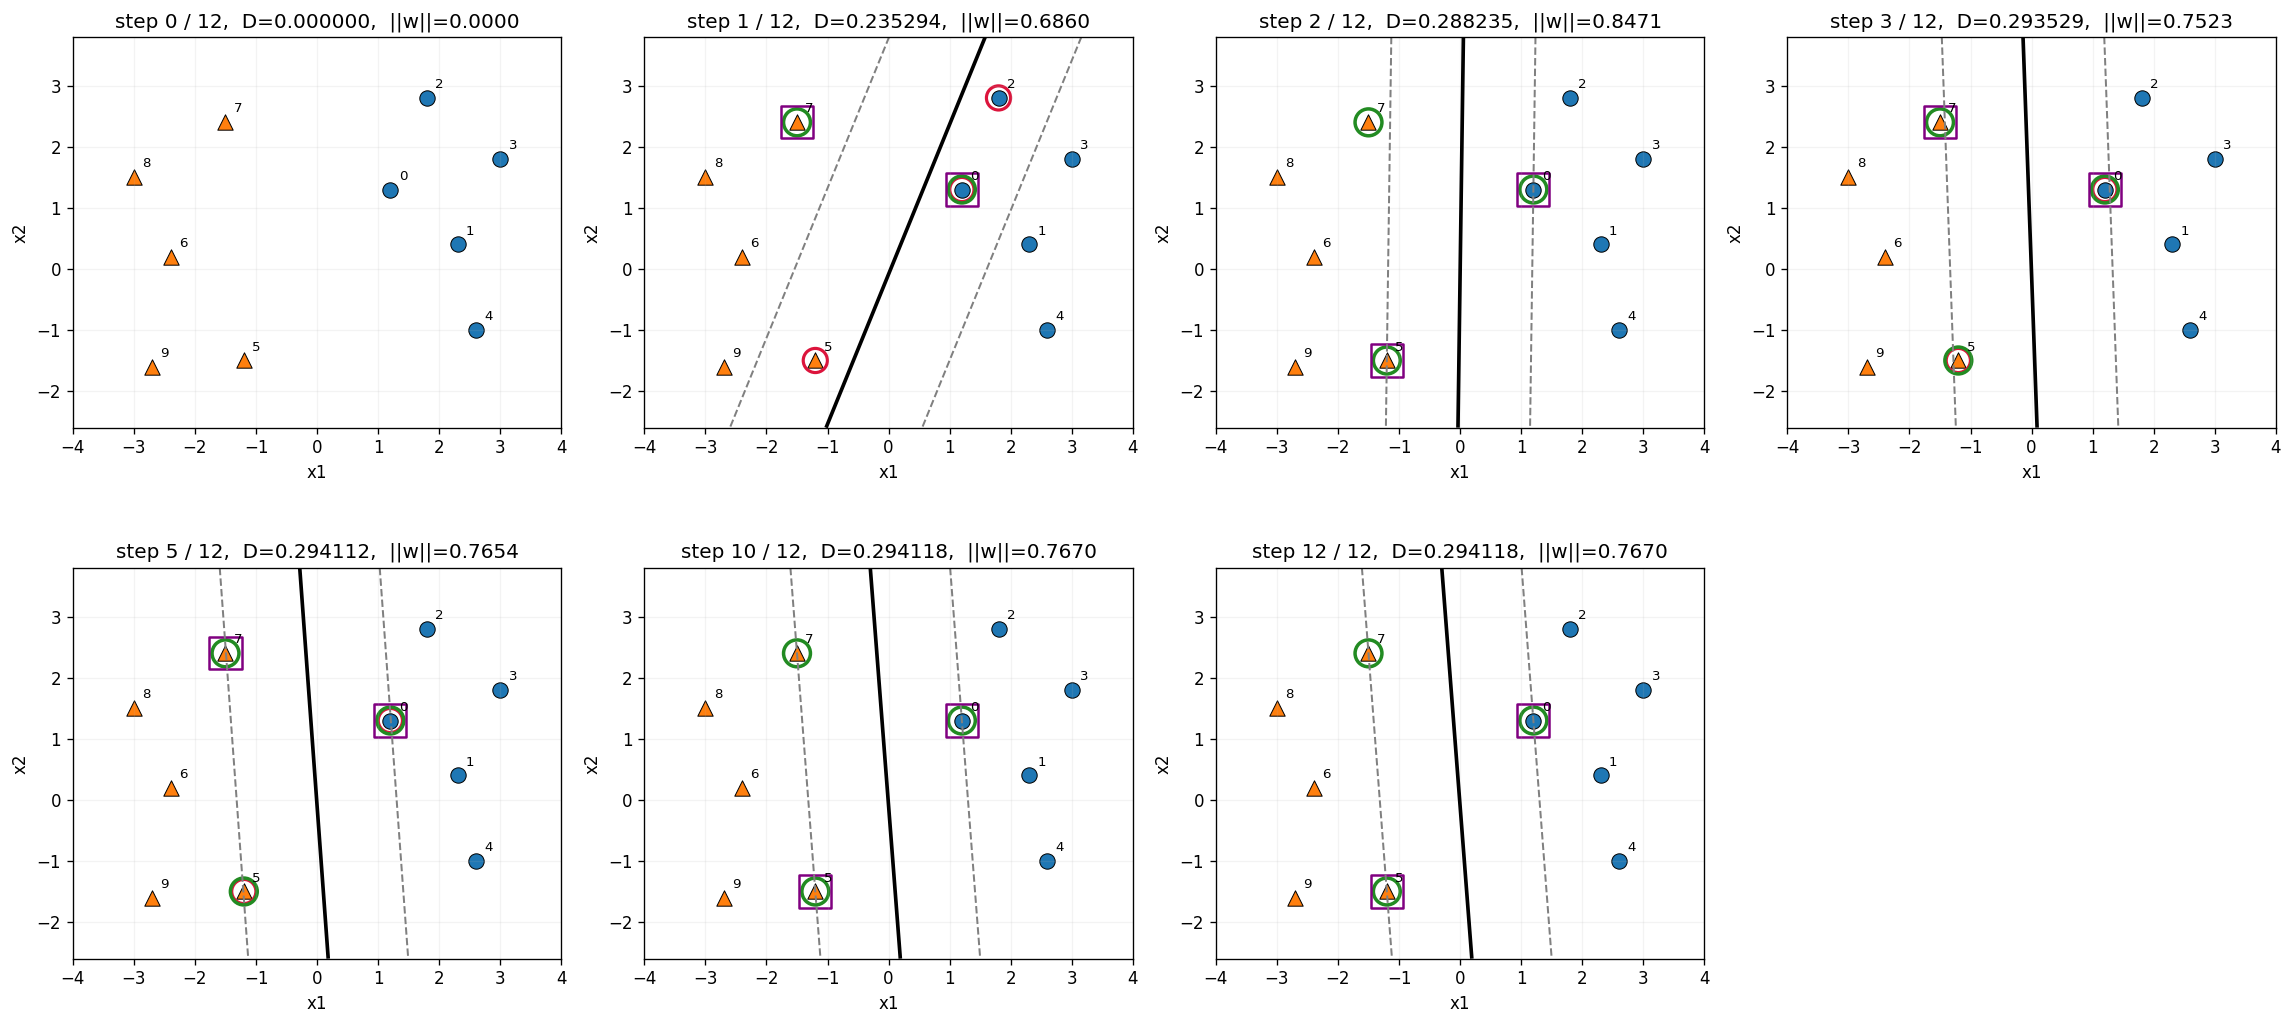

In [4]:
def compute_bias(w, lam=None, final=False):
    if np.linalg.norm(w) < 1e-12:
        return 0.0
    if final and lam is not None:
        ids = np.flatnonzero(lam > 1e-7)
        if len(ids):
            return float(np.mean(y[ids] - X[ids] @ w))
    return float(-0.5*(np.min(X[y>0] @ w)+np.max(X[y<0] @ w)))


def plot_state(step, ax=None, final=False):
    rec = history[step]
    lam = rec['lam']; w = reconstruct_w(lam)
    b0 = compute_bias(w, lam, final=final)
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5.5))
    for lab,color,marker in [(1,'tab:blue','o'),(-1,'tab:orange','^')]:
        mask = y==lab
        ax.scatter(X[mask,0],X[mask,1],s=85,marker=marker,c=color,
                   edgecolors='black',linewidths=.6)
    for idx, p in enumerate(X):
        ax.annotate(str(idx), p, xytext=(5,6), textcoords='offset points',fontsize=8)
    sx = np.linspace(X[:,0].min()-1, X[:,0].max()+1, 350)
    sy = np.linspace(X[:,1].min()-1, X[:,1].max()+1, 350)
    if np.linalg.norm(w)>1e-10:
        xx, yy = np.meshgrid(sx, sy)
        scores = w[0]*xx + w[1]*yy + b0
        ax.contour(xx, yy, scores, levels=[-1,0,1],
                   colors=['gray','black','gray'],linestyles=['--','-','--'],linewidths=[1.2,2.2,1.2])
        signed = y * (X@w+b0)
        violating = signed < 1-1e-5
        if np.any(violating):
            ax.scatter(X[violating,0],X[violating,1],s=210,
                       facecolors='none',edgecolors='crimson',linewidths=1.9)
    sv = lam>1e-7
    if np.any(sv):
        ax.scatter(X[sv,0],X[sv,1],s=260,facecolors='none',
                   edgecolors='forestgreen',linewidths=2.1)
    if rec['pair'] is not None:
        for k in rec['pair']:
            ax.scatter(*X[k],s=370,marker='s',facecolors='none',
                       edgecolors='purple',linewidths=1.5)
    ax.set(xlim=(sx.min(),sx.max()),ylim=(sy.min(),sy.max()),
           xlabel='x1',ylabel='x2',
           title=f"step {step} / {len(history)-1},  D={rec['D']:.6f},  ||w||={np.linalg.norm(w):.4f}")
    ax.grid(alpha=.15); ax.set_aspect('equal', adjustable='box')
    return ax

# Green rings: lambda>0, red rings: margin violation, purple squares: last updated pair.
selected = sorted(set([0,1,2,3,5,10,20,40,len(history)-1]) & set(range(len(history))))
fig, axs = plt.subplots(2, int(np.ceil(len(selected)/2)),
                        figsize=(4.8*int(np.ceil(len(selected)/2)), 9), squeeze=False)
for ax in axs.ravel(): ax.axis('off')
for ax, k in zip(axs.ravel(), selected):
    ax.axis('on'); plot_state(k, ax=ax, final=(k==len(history)-1))
plt.tight_layout(); plt.show()

## 5. ステップを1つずつ選ぶ（Notebook操作）

以下の `STEP` を 0, 1, 2, ... に変えて再実行すると、任意の更新直後を大きな図で確認できます。更新された2点を紫の四角で示します。

last updated pair: (0, 7)
lambda: [0.29353 0.      0.      0.      0.      0.09706 0.      0.19647 0.
 0.     ]
dual objective: 0.2941117647058824
w: [0.76341 0.05565]


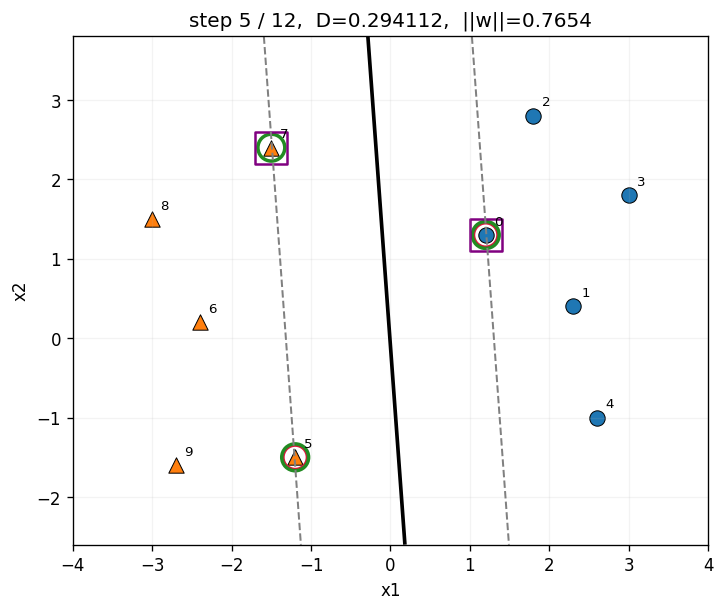

In [5]:
STEP = min(5, len(history)-1)  # ← ここを変更する
rec = history[STEP]
print('last updated pair:', rec['pair'])
print('lambda:', rec['lam'])
print('dual objective:', rec['D'])
print('w:', reconstruct_w(rec['lam']))
plot_state(STEP, final=(STEP==len(history)-1))
plt.show()

## 6. 双対目的関数・各係数の学習曲線

目的関数が更新ごとに非減少になること、係数が0から変化し一部だけ正になることを見ます。

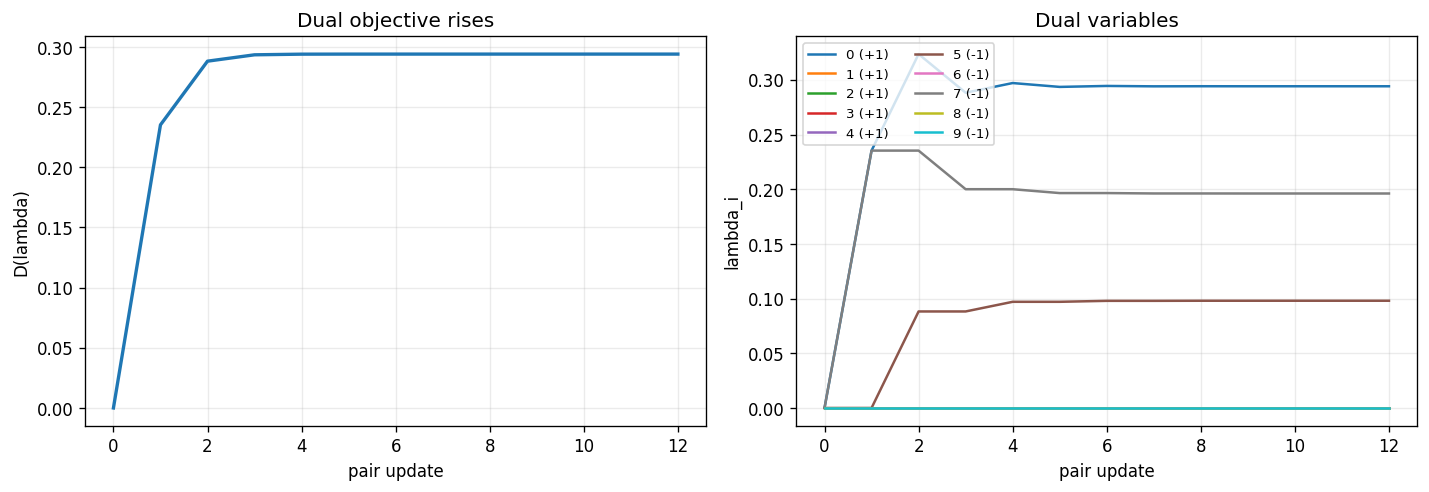

In [6]:
LAMS = np.array([r['lam'] for r in history])
DS = np.array([r['D'] for r in history])
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(12,4.2))
ax1.plot(DS, lw=2); ax1.set(title='Dual objective rises',xlabel='pair update',ylabel='D(lambda)')
for i in range(len(y)):
    ax2.plot(LAMS[:,i], label=f'{i} ({int(y[i]):+d})')
ax2.set(title='Dual variables',xlabel='pair update',ylabel='lambda_i')
ax2.legend(ncol=2,fontsize=8)
for ax in (ax1,ax2): ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

## 7. SciPyのQP最適化結果と比較

教材のペア更新は学習を可視化するためのものです。正しい最適値と一致するか、`scipy.optimize.minimize(method="SLSQP")` で双対問題を独立に解いて確認します。SLSQPは汎用の制約付き最適化法であり、QP専用ソルバーではありません。

In [7]:
def objective_min(lam):
    return -dual_value(lam)

def jac_min(lam):
    return -dual_grad(lam)

res = minimize(objective_min, np.zeros(n_samples), jac=jac_min,
               method='SLSQP', bounds=[(0,None)]*n_samples,
               constraints=[{'type':'eq','fun':lambda l: float(y@l),
                             'jac':lambda l: y}],
               options={'ftol':1e-12,'maxiter':20000})
assert res.success, res.message
lam_star = res.x
w_star = reconstruct_w(lam_star)
sv_ids = np.flatnonzero(lam_star > 1e-7)
b_star = compute_bias(w_star, lam_star, final=True)

print('SLSQP success:', res.message)
print('D(Pair ascent) =', dual_value(history[-1]['lam']))
print('D(SLSQP)       =', dual_value(lam_star))
print('difference     =', abs(dual_value(history[-1]['lam'])-dual_value(lam_star)))
print('w*, w0*        =', w_star, b_star)
print('support indices=', sv_ids)
print('margin width 2/||w|| =', 2/np.linalg.norm(w_star))
assert abs(dual_value(history[-1]['lam'])-dual_value(lam_star)) < 1e-5

SLSQP success: Optimization terminated successfully
D(Pair ascent) = 0.2941176470582353
D(SLSQP)       = 0.29411764705882343
difference     = 5.881406472951767e-13
w*, w0*        = [0.76471 0.05882] 0.0058823536304794715
support indices= [0 5 7]
margin width 2/||w|| = 2.607681000070529


## 8. KKT条件を数値で検査

最適解が満たす条件：

1. **主実行可能性**：$m_k=y_k(w^Tx_k+w_0)\ge1$
2. **双対実行可能性**：$\lambda_k\ge0$
3. **双対等式**：$\sum_k\lambda_k y_k=0$
4. **相補性**：$\lambda_k(m_k-1)=0$
5. **停留条件**：$w=\sum_k\lambda_ky_kx_k$

相補性から、最適解で $\lambda_k>0$ のデータは $m_k\approx1$ でありマージン上にあります。逆に、マージン上の点すべてが正の双対係数を持つとは限りません。

In [8]:
margins = y*(X@w_star+b_star)
slack_hard = margins-1
kkt_product = lam_star * slack_hard
print(' idx | label |    lambda | y*g(x) | lambda*(y*g-1) | SV')
print('-'*72)
for k in range(n_samples):
    print(f'{k:4d} | {y[k]:+5.0f} | {lam_star[k]:9.6f} | {margins[k]:6.4f} | '
          f'{kkt_product[k]:15.3e} | {lam_star[k]>1e-7}')
print('min margin          :', margins.min())
print('lambda^T*y          :', lam_star@y)
print('max complementarity :', np.max(np.abs(kkt_product)))
print('primal objective    :', 0.5*(w_star@w_star))
print('dual objective      :', dual_value(lam_star))
print('duality gap         :', 0.5*(w_star@w_star)-dual_value(lam_star))
assert margins.min() >= 1-1e-5
assert np.max(np.abs(kkt_product)) < 1e-5
assert abs((0.5*w_star@w_star)-dual_value(lam_star)) < 1e-5

 idx | label |    lambda | y*g(x) | lambda*(y*g-1) | SV
------------------------------------------------------------------------
   0 |    +1 |  0.294118 | 1.0000 |      -6.648e-09 | True
   1 |    +1 |  0.000000 | 1.7882 |       6.584e-17 | False
   2 |    +1 |  0.000000 | 1.5471 |       0.000e+00 | False
   3 |    +1 |  0.000000 | 2.4059 |       0.000e+00 | False
   4 |    +1 |  0.000000 | 1.9353 |       0.000e+00 | False
   5 |    -1 |  0.098039 | 1.0000 |      -2.511e-09 | True
   6 |    -1 |  0.000000 | 1.8176 |       0.000e+00 | False
   7 |    -1 |  0.196078 | 1.0000 |       5.900e-10 | True
   8 |    -1 |  0.000000 | 2.2000 |       0.000e+00 | False
   9 |    -1 |  0.000000 | 2.1529 |       0.000e+00 | False
min margin          : 0.9999999743860319
lambda^T*y          : 6.661338147750939e-16
max complementarity : 6.6484555127207985e-09
primal objective    : 0.2941176384892376
dual objective      : 0.29411764705882343
duality gap         : -8.569585818740677e-09


## 9. 最終的な決定境界とマージン

黒線が $g(x)=0$、灰色の破線が $g(x)=\pm1$ です。緑色の輪で囲まれた点がサポートベクトルです。

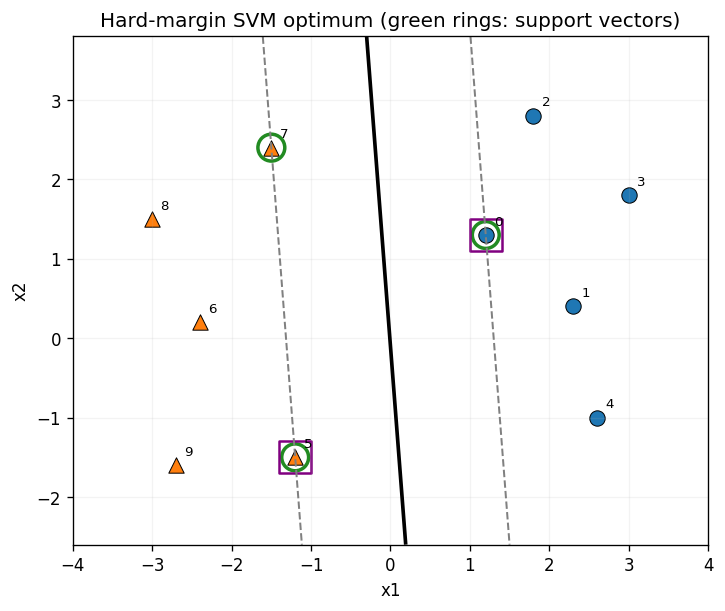

In [9]:
ax = plot_state(len(history)-1, final=True)
ax.set_title('Hard-margin SVM optimum (green rings: support vectors)')
plt.show()

## 10. ハードマージンとパーセプトロンの比較

パーセプトロンは誤分類（境界上含む）を修正する更新 $w\leftarrow w+\eta y_kx_k$ を行います。バイアスも同時に更新します。線形分離できれば正しく分類する直線は得られますが、**その直線は一般に最大マージンとは限りません**。

比較のため、同じ10点を使って実際にパーセプトロンを学習させます。

perceptron w,b,updates: [ 2.7 -1.1] 0.0 2
perceptron min signed distance: 0.5453655007531781
SVM min signed distance: 1.3038405000352644


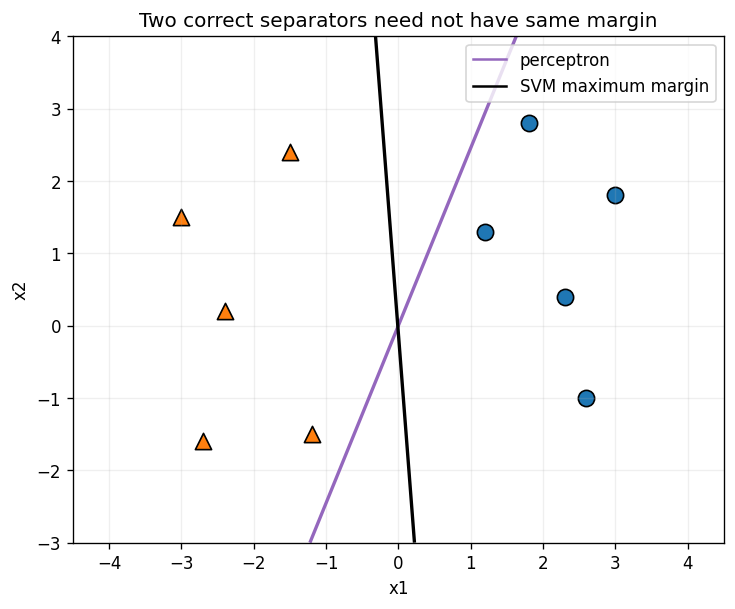

In [10]:
def perceptron_fit(X,y,eta=1.0,max_epochs=1000):
    wp=np.zeros(X.shape[1]); bp=0.0
    updates=0
    for epoch in range(max_epochs):
        mistakes=0
        for xk,yk in zip(X,y):
            if yk*(wp@xk+bp)<=0:
                wp+=eta*yk*xk; bp+=eta*yk
                updates+=1; mistakes+=1
        if mistakes==0: break
    return wp,bp,updates

wp,bp,nupd = perceptron_fit(X,y)
print('perceptron w,b,updates:',wp,bp,nupd)
print('perceptron min signed distance:', np.min(y*(X@wp+bp))/np.linalg.norm(wp))
print('SVM min signed distance:', 1/np.linalg.norm(w_star))
fig,ax=plt.subplots(figsize=(7,5.5))
for lab,col,marker in [(1,'tab:blue','o'),(-1,'tab:orange','^')]:
    mask=y==lab;ax.scatter(X[mask,0],X[mask,1],c=col,marker=marker,s=95,edgecolor='black')
xx,yy=np.meshgrid(np.linspace(-4.5,4.5,200),np.linspace(-3,4,200))
ax.contour(xx,yy,wp[0]*xx+wp[1]*yy+bp,levels=[0],colors=['tab:purple'],linewidths=2)
ax.contour(xx,yy,w_star[0]*xx+w_star[1]*yy+b_star,levels=[0],colors=['black'],linewidths=2)
ax.plot([],[],color='tab:purple',label='perceptron')
ax.plot([],[],color='black',label='SVM maximum margin')
ax.set(xlabel='x1',ylabel='x2',title='Two correct separators need not have same margin')
ax.legend();ax.grid(alpha=.2);ax.set_aspect('equal',adjustable='box');plt.show()

## 11. 演習課題

**演習1（更新の意味）**：最初の更新で選ばれたペアを確認し、その2点の $\lambda$ がなぜ同時に増えるのか、$\sum_k y_k\lambda_k=0$ から説明しましょう。

**演習2（初期値）**：`history[0]` の $\lambda=0$ は双対制約を満たします。しかし主問題の全制約を満たしません。なぜ矛盾しないのでしょうか。

**演習3（データ数を変更）**：`X, y` の各クラスから1点ずつ削除して **8点** にし、セル2以降を再実行してください。更新回数・サポートベクトル・マージン幅はどう変わるでしょうか。

**演習4（誤分類不能なデータ）**：同じ座標に相反するラベルを与えた場合、ハードマージンSVMの主問題は実行不可能になります。なぜでしょうか。※教材のペア更新はこの場合終了しない場合があるため、実行前に `max_steps` を小さく設定してください。

**演習5（双対の理解）**：$H$ の非零固有値を観察し、$H=ZZ^T$ が半正定値になる証明を説明してください。

### 解答のヒント
- 1：異なるラベルの2点なら $y_i=+1,y_j=-1$ で、$\Delta\lambda_i=\Delta\lambda_j$ とすれば等式制約が保存されます。
- 2：双対変数の実行可能性と主変数の実行可能性は別物です。KKT全体は最適解で検査します。
- 4：同じ $x$ に対して $g(x)\ge1$ と $g(x)\le-1$ を同時に要求できません。

**補足**：厳密なSMOの実装にはペアの選択基準、バイアス更新、数値誤差対策、停止判定などが必要です。ここでは数学的更新を理解することを優先しています。

## 12. 更新履歴と両方の最終解をまとめて検証する

リポジトリへの追加時に補足した検証です。すべての更新で双対実行可能性と目的関数の非減少を確認し、ペア更新法とSLSQPの**それぞれ**の最終解に対して主実行可能性・相補性・双対ギャップを検査します。バイアスを暫定的に置いた途中状態の主実行可能性は要求しません。

以下は、この10点のデータに対する数値検証です。停止判定は最大のペア改善量による教材用の基準であり、一般のデータに対する収束保証やLIBSVMとの同一性を示すものではありません。

In [11]:
history_lambdas = np.array([record['lam'] for record in history])
history_objectives = np.array([record['D'] for record in history])
equality_residual = float(np.max(np.abs(history_lambdas @ y)))
assert history_lambdas.min() >= -1e-9
assert equality_residual < 1e-8
assert np.all(np.diff(history_objectives) >= -1e-9)
print('all-step equality residual:', equality_residual)
print('smallest objective increase:', np.diff(history_objectives).min())

verification = {}
for name, coefficients in [('pair_ascent', history[-1]['lam']), ('slsqp', lam_star)]:
    weights = reconstruct_w(coefficients)
    bias = compute_bias(weights, coefficients, final=True)
    signed_margins = y * (X @ weights + bias)
    primal = float(0.5 * (weights @ weights))
    dual = dual_value(coefficients)
    complementarity = float(np.max(np.abs(coefficients * (signed_margins - 1))))
    assert coefficients.min() >= -1e-9
    assert abs(y @ coefficients) < 1e-8
    assert signed_margins.min() >= 1 - 1e-5
    assert complementarity < 1e-5
    assert abs(primal - dual) < 1e-5
    verification[name] = dict(
        min_margin=float(signed_margins.min()),
        max_complementarity=complementarity,
        absolute_duality_gap=abs(primal - dual),
    )
    print(name, verification[name])

assert np.allclose(reconstruct_w(history[-1]['lam']), w_star, atol=1e-5, rtol=0)
assert abs(dual_value(history[-1]['lam']) - dual_value(lam_star)) < 1e-5
print('All learning-process checks passed.')


all-step equality residual: 5.551115123125783e-17
smallest objective increase: 5.294042981773828e-12
pair_ascent {'min_margin': 0.9999989999999999, 'max_complementarity': 3.921576470701003e-07, 'absolute_duality_gap': 5.882364705334098e-07}
slsqp {'min_margin': 0.9999999743860319, 'max_complementarity': 6.6484555127207985e-09, 'absolute_duality_gap': 8.569585818740677e-09}
All learning-process checks passed.
